# Imports

In [4]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_percentage_error
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.decomposition import PCA
from sklearn.neural_network import MLPRegressor
from sklearn.inspection import permutation_importance

import tensorflow as tf
import keras
from keras.models import Sequential
from keras.layers import Dense, Dropout
from keras.optimizers import Adam
from keras.callbacks import EarlyStopping

os.makedirs('images', exist_ok=True)

# Helper functions

In [5]:
def scatter_real_vs_predicted(y_pred, title, filename):
    plt.figure(figsize=(10, 6))
    plt.scatter(y_test, y_pred, alpha=0.5, color='blue')
    plt.title(title)
    plt.xlabel('Real price')
    plt.ylabel('Predicted price')
    plt.grid(True, linestyle=':', alpha=0.7)
    plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linestyle='--')
    plt.savefig(f'images/{filename}.png')
    plt.show()


def plot_dominant_factors(dominant_factors, column, filename):
    plt.figure(figsize=(8, 4))
    plt.barh(dominant_factors['Feature'][::-1], dominant_factors[column][::-1])
    plt.title('Top 10 dominant price-driving factors')
    plt.tight_layout()
    plt.savefig(f'images/{filename}.png')
    plt.show()

# Data loading and preprocessing

In [6]:
data = pd.read_csv('AmesHousing.csv')
X = data.drop('SalePrice', axis=1)
y = data['SalePrice']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=23)

X_train_num = X_train.select_dtypes(include='number').copy()
X_test_num = X_test.select_dtypes(include='number').copy()

lacks_num = X_train_num.isnull().sum()
print("Missing values (numeric columns):")
print(lacks_num[lacks_num > 0])

Missing values (numeric columns):
Lot Frontage      388
Mas Vnr Area       18
Bsmt Full Bath      1
Bsmt Half Bath      1
Garage Yr Blt     118
Garage Cars         1
Garage Area         1
dtype: int64


### Missing value imputation

In [7]:
X_train_num['Lot Frontage'] = X_train_num['Lot Frontage'].fillna(X_train_num['Lot Frontage'].median())
X_train_num['Garage Yr Blt'] = X_train_num['Garage Yr Blt'].fillna(X_train_num['Garage Yr Blt'].median())
X_train_num = X_train_num.fillna(0)

X_test_num['Lot Frontage'] = X_test_num['Lot Frontage'].fillna(X_train_num['Lot Frontage'].median())
X_test_num['Garage Yr Blt'] = X_test_num['Garage Yr Blt'].fillna(X_train_num['Garage Yr Blt'].median())
X_test_num = X_test_num.fillna(0)

# Linear Regression - numeric features only (baseline)

Mean error is 15.0 %


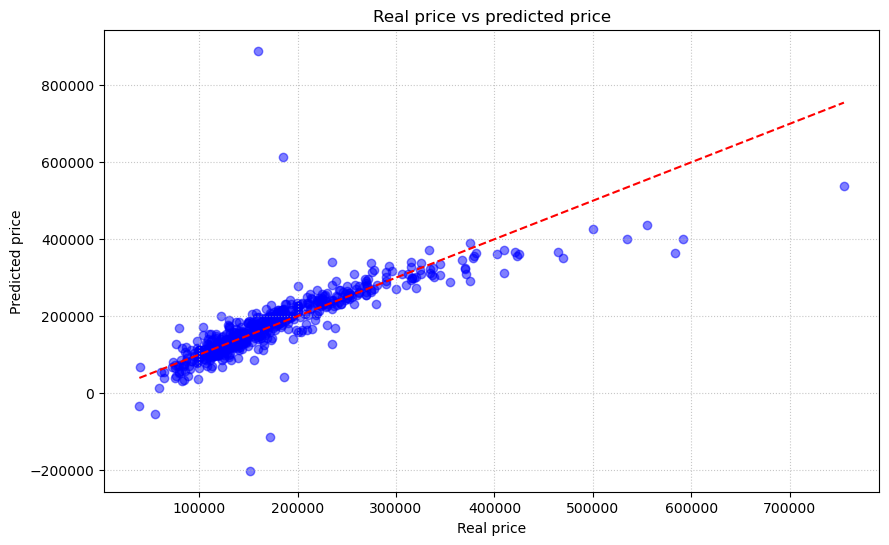

In [8]:
model = LinearRegression()
model.fit(X_train_num, y_train)
y_pred = model.predict(X_test_num)
mape = mean_absolute_percentage_error(y_test, y_pred)
print(f"Mean error is {mape*100:.1f} %")

scatter_real_vs_predicted(y_pred, 'Real price vs predicted price', 'linear_num')

### Dominant numeric factors

In [9]:
scaler_num = StandardScaler()
X_train_num_scaled = scaler_num.fit_transform(X_train_num)
model_scaled = LinearRegression()
model_scaled.fit(X_train_num_scaled, y_train)

factors_num = pd.DataFrame({'Feature': X_train_num.columns, 'Coefficient': model_scaled.coef_})
factors_num['AbsCoefficient'] = np.abs(factors_num['Coefficient'])
dominant_factors_num = factors_num.sort_values(by='AbsCoefficient', ascending=False).head(5)
print(dominant_factors_num[['Feature', 'Coefficient']])

         Feature   Coefficient
17   Gr Liv Area -6.581955e+16
15    2nd Flr SF  5.672720e+16
14    1st Flr SF  5.111759e+16
10  BsmtFin SF 1  3.702124e+16
12   Bsmt Unf SF  3.687638e+16


# Linear Regression - full feature set (numeric + categorical)

Mean error is 10.9 %


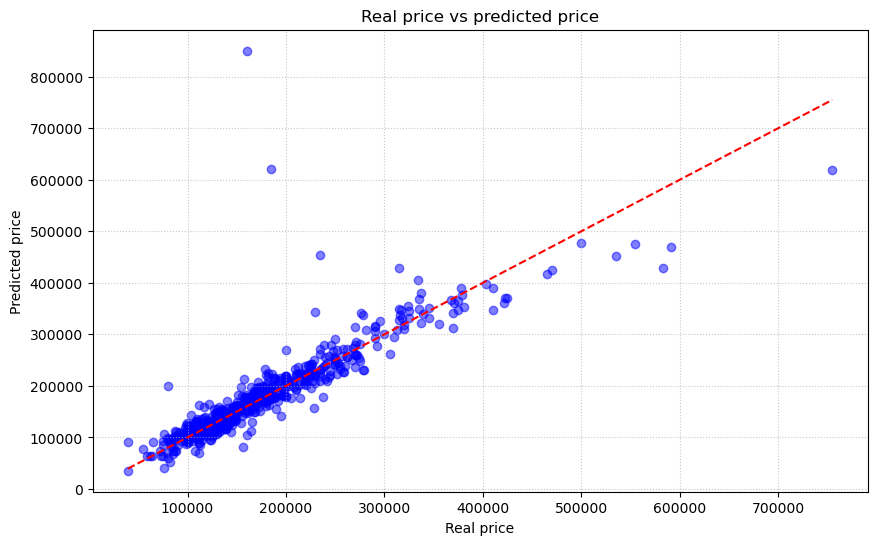

In [10]:
X_train_cat = X_train.select_dtypes(exclude='number')
X_test_cat = X_test.select_dtypes(exclude='number')
X_train_cat = X_train_cat.fillna('Lack')
X_test_cat = X_test_cat.fillna('Lack')
X_train_cat_num = pd.get_dummies(X_train_cat)
X_test_cat_num = pd.get_dummies(X_test_cat)
X_test_cat_num = X_test_cat_num.reindex(columns=X_train_cat_num.columns, fill_value=0)

X_train_full = pd.concat([X_train_num, X_train_cat_num], axis=1)
X_test_full = pd.concat([X_test_num, X_test_cat_num], axis=1)

model.fit(X_train_full, y_train)
y_pred = model.predict(X_test_full)
mape = mean_absolute_percentage_error(y_test, y_pred)
print(f"Mean error is {mape*100:.1f} %")
scatter_real_vs_predicted(y_pred, 'Real price vs predicted price', 'linear_full')

### Dominant factors (full model)

In [11]:
scaler_full = StandardScaler()
X_train_full_scaled = scaler_full.fit_transform(X_train_full)

model_full_scaled = LinearRegression()
model_full_scaled.fit(X_train_full_scaled, y_train)

factors_full = pd.DataFrame({'Feature': X_train_full.columns, 'Coefficient': model_full_scaled.coef_})
factors_full['AbsCoefficient'] = np.abs(factors_full['Coefficient'])
dominant_factors_full = factors_full.sort_values(by='AbsCoefficient', ascending=False).head(20)
print(dominant_factors_full[['Feature', 'Coefficient']])

                    Feature   Coefficient
314   Sale Condition_Normal -1.973141e+14
179           Exter Qual_TA -1.949949e+14
178           Exter Qual_Gd -1.899756e+14
259      Garage Type_Attchd  1.644550e+14
243         Kitchen Qual_TA -1.631053e+14
274          Garage Qual_TA -1.598853e+14
242         Kitchen Qual_Gd -1.598401e+14
263      Garage Type_Detchd  1.472801e+14
315  Sale Condition_Partial -1.455203e+14
278        Garage Cond_Lack -1.440647e+14
309           Sale Type_WD  -1.284348e+14
194          Bsmt Qual_Lack  1.265753e+14
310  Sale Condition_Abnorml -1.238548e+14
184           Exter Cond_TA  1.190936e+14
221      BsmtFin Type 2_Unf -1.084250e+14
283           Paved Drive_Y  1.070843e+14
182           Exter Cond_Gd  1.066098e+14
120      House Style_1Story  1.047394e+14
306           Sale Type_New -1.044189e+14
270          Garage Qual_Fa -1.033285e+14


# Random Forest Regression

Mean error is 10.5 %


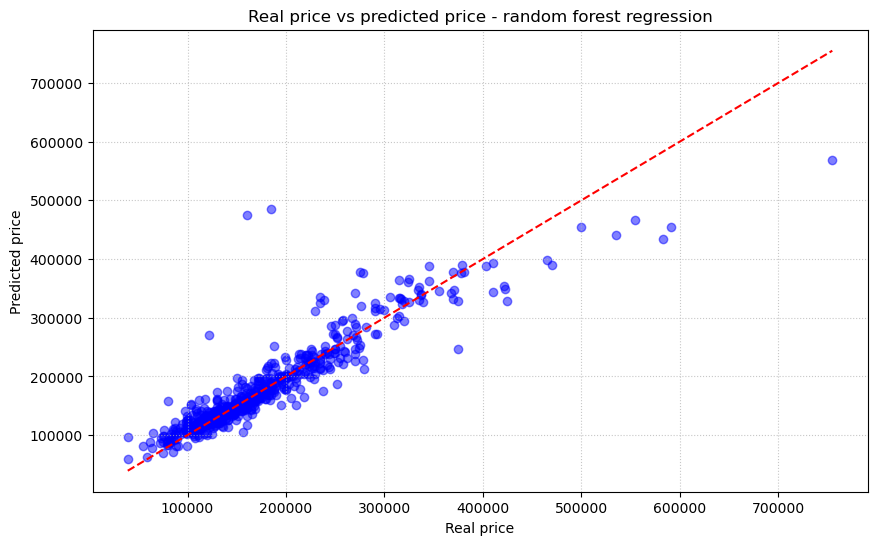

In [12]:
model_forest = RandomForestRegressor(n_estimators=100, random_state=23)
model_forest.fit(X_train_full, y_train)
y_pred_forest = model_forest.predict(X_test_full)
mape_forest = mean_absolute_percentage_error(y_test, y_pred_forest)
print(f"Mean error is {mape_forest*100:.1f} %")
scatter_real_vs_predicted(y_pred_forest, 'Real price vs predicted price - random forest regression', 'forest_scatter')

### Dominant factors - Random Forest

          Feature  Importance
5    Overall Qual    0.617707
17    Gr Liv Area    0.112603
14     1st Flr SF    0.034754
13  Total Bsmt SF    0.029936
20      Full Bath    0.027385
10   BsmtFin SF 1    0.025089
4        Lot Area    0.013839
15     2nd Flr SF    0.012546
7      Year Built    0.011549
28    Garage Area    0.009164


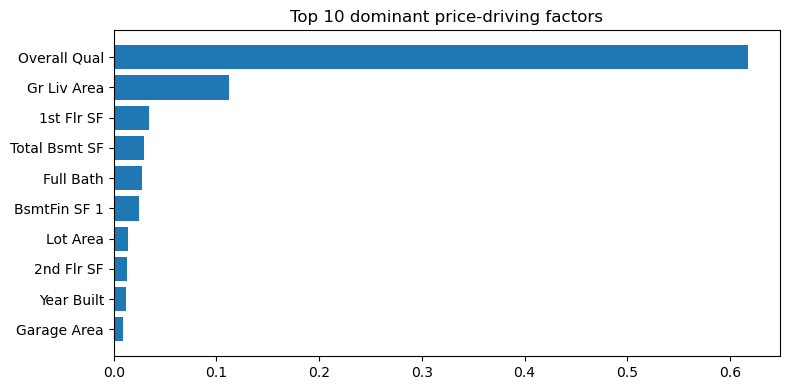

In [13]:
factors_forest = pd.DataFrame({'Feature': X_train_full.columns, 'Importance': model_forest.feature_importances_})
dominant_factors_forest = factors_forest.sort_values(by='Importance', ascending=False).head(10)
print(dominant_factors_forest)
plot_dominant_factors(dominant_factors_forest, 'Importance', 'forest_factors')

# PCA - dimensionality reduction analysis

In [14]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_full)
X_test_scaled = scaler.transform(X_test_full)
p_values = [0.70, 0.75, 0.80, 0.85, 0.90, 0.95, 0.99]

mape_linear_results = []
mape_forest_results = []
n_components_results = []
for p in p_values:
    pca = PCA(n_components=p, random_state=23)
    X_train_pca = pca.fit_transform(X_train_scaled)
    X_test_pca = pca.transform(X_test_scaled)
    n_components_results.append(X_train_pca.shape[1])
    print(f"Number of components for {p} variance: {X_train_pca.shape[1]}")

    model_linear = LinearRegression()
    model_linear.fit(X_train_pca, y_train)
    y_pred_linear = model_linear.predict(X_test_pca)
    mape_linear = mean_absolute_percentage_error(y_test, y_pred_linear)
    mape_linear_results.append(mape_linear * 100)

    model_forest = RandomForestRegressor(n_estimators=100, random_state=23)
    model_forest.fit(X_train_pca, y_train)
    y_pred_forest = model_forest.predict(X_test_pca)
    mape_forest = mean_absolute_percentage_error(y_test, y_pred_forest)
    mape_forest_results.append(mape_forest * 100)

Number of components for 0.7 variance: 96
Number of components for 0.75 variance: 111
Number of components for 0.8 variance: 127
Number of components for 0.85 variance: 146
Number of components for 0.9 variance: 168
Number of components for 0.95 variance: 196
Number of components for 0.99 variance: 232


### MAPE vs. explained variance / number of components

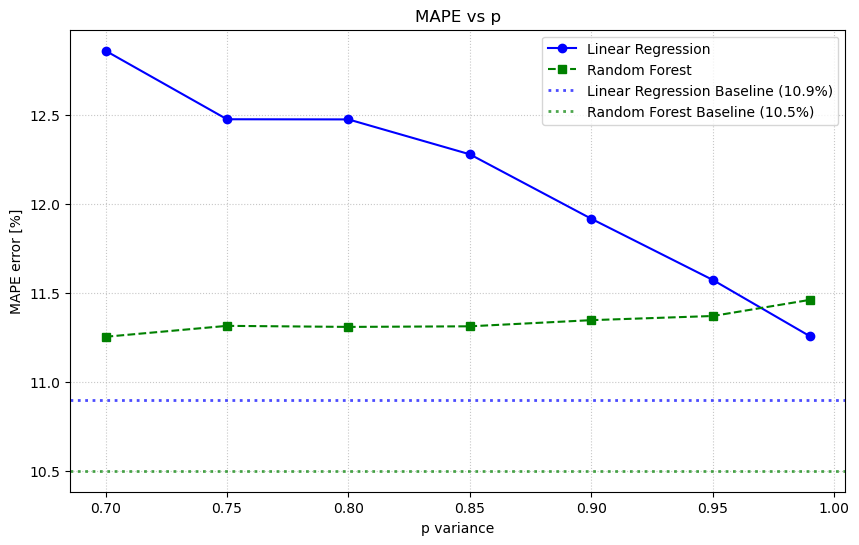

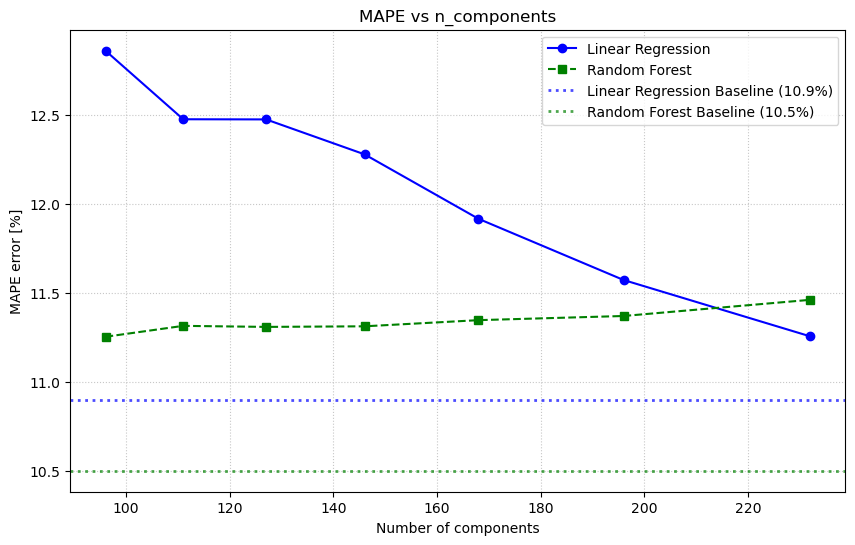

In [15]:
plt.figure(figsize=(10, 6))
plt.plot(p_values, mape_linear_results, marker='o', linestyle='-', color='blue', label='Linear Regression')
plt.plot(p_values, mape_forest_results, marker='s', linestyle='--', color='green', label='Random Forest')
plt.axhline(y=10.9, color='blue', linestyle=':', alpha=0.7, linewidth=2, label='Linear Regression Baseline (10.9%)')
plt.axhline(y=10.5, color='green', linestyle=':', alpha=0.7, linewidth=2, label='Random Forest Baseline (10.5%)')
plt.title('MAPE vs p')
plt.xlabel('p variance')
plt.ylabel('MAPE error [%]')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.7)
plt.savefig('images/pca_mape_p.png')
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(n_components_results, mape_linear_results, marker='o', linestyle='-', color='blue', label='Linear Regression')
plt.plot(n_components_results, mape_forest_results, marker='s', linestyle='--', color='green', label='Random Forest')
plt.axhline(y=10.9, color='blue', linestyle=':', alpha=0.7, linewidth=2, label='Linear Regression Baseline (10.9%)')
plt.axhline(y=10.5, color='green', linestyle=':', alpha=0.7, linewidth=2, label='Random Forest Baseline (10.5%)')
plt.title('MAPE vs n_components')
plt.xlabel('Number of components')
plt.ylabel('MAPE error [%]')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.7)
plt.savefig('images/pca_mape_components.png')
plt.show()

### Dominant factors - first principal component

In [16]:
pca = PCA(n_components=0.95, random_state=23)
pca.fit(X_train_scaled)
factors_pca = pd.DataFrame({'Feature': X_train_full.columns, 'Loading': pca.components_[0]})
factors_pca['AbsLoading'] = np.abs(factors_pca['Loading'])
dominant_factors_pca = factors_pca.sort_values(by='AbsLoading', ascending=False).head(10)
print('The first principal component driving factors')
print(dominant_factors_pca[['Feature', 'Loading']])

The first principal component driving factors
              Feature   Loading
7          Year Built  0.192689
5        Overall Qual  0.183142
26      Garage Yr Blt  0.168013
27        Garage Cars  0.162142
179     Exter Qual_TA -0.160069
187  Foundation_PConc  0.158840
8      Year Remod/Add  0.158325
28        Garage Area  0.152635
178     Exter Qual_Gd  0.147394
243   Kitchen Qual_TA -0.139606


# MLP Regressor

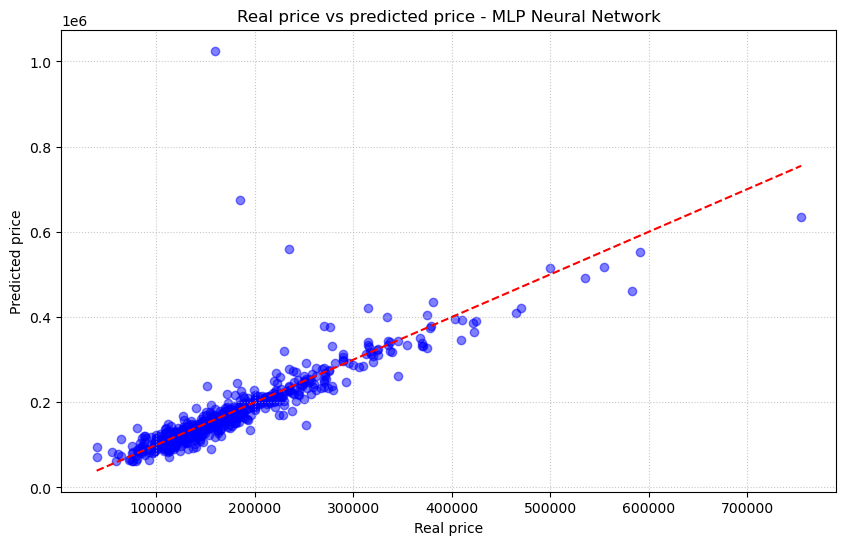

Mean error for MLP Neural Network is 11.4 %


In [17]:
model_r_net = MLPRegressor(hidden_layer_sizes=(256, 128, 128, 128), max_iter=10000, learning_rate_init=0.01, random_state=23)

model_r_net.fit(X_train_scaled, y_train)
y_pred_r_net = model_r_net.predict(X_test_scaled)
mape_r_net = mean_absolute_percentage_error(y_test, y_pred_r_net)
scatter_real_vs_predicted(y_pred_r_net, 'Real price vs predicted price - MLP Neural Network', 'mlp_scatter')
print(f"Mean error for MLP Neural Network is {mape_r_net*100:.1f} %")

### Dominant factors - MLP (permutation importance)

                  Feature  Importance
286            Pool QC_Gd    0.066308
109      Condition 2_PosN    0.021280
15             2nd Flr SF    0.015655
52          Lot Shape_IR3    0.013515
6            Overall Cond    0.012955
87   Neighborhood_NridgHt    0.010919
5            Overall Qual    0.009985
295     Misc Feature_Gar2    0.008036
54       Land Contour_Bnk    0.007568
93   Neighborhood_StoneBr    0.007276


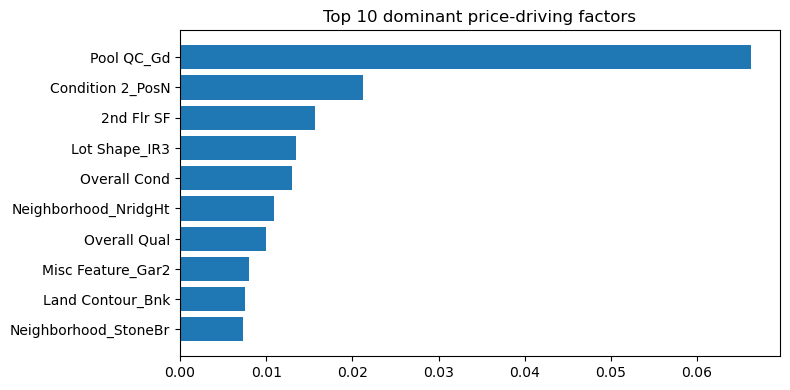

In [18]:
perm_mlp = permutation_importance(model_r_net, X_test_scaled, y_test, n_repeats=5, random_state=23)
factors_mlp = pd.DataFrame({'Feature': X_train_full.columns, 'Importance': perm_mlp.importances_mean})
dominant_factors_mlp = factors_mlp.sort_values(by='Importance', ascending=False).head(10)
print(dominant_factors_mlp)
plot_dominant_factors(dominant_factors_mlp, 'Importance', 'mlp_factors')

# Deep Neural Network (Keras)

c:\Anaconda\Lib\site-packages\keras\src\layers\core\dense.py:92: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step


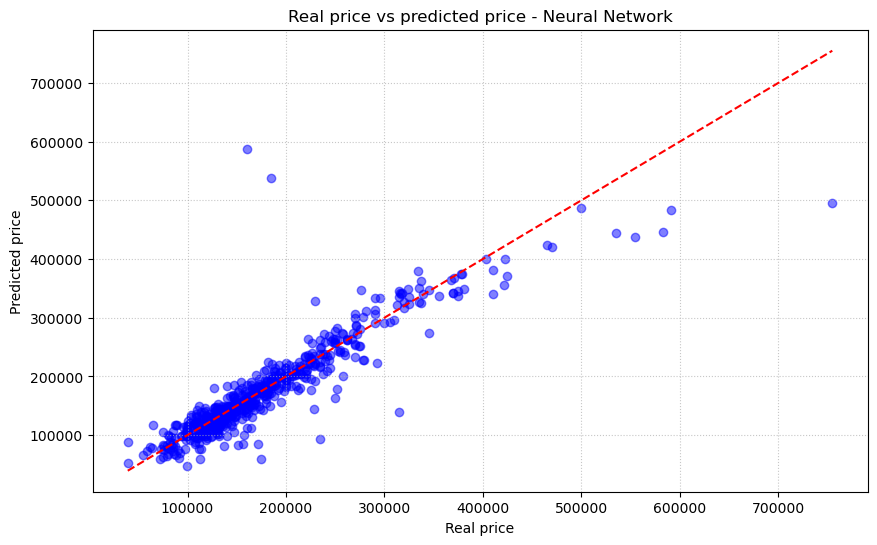

Mean error for Neural Network is 10.9 %


In [19]:
tf.keras.utils.set_random_seed(23)
tf.config.experimental.enable_op_determinism()

input_shape = X_train_scaled.shape[1]
batch_size = 64
epochs = 200

model_net = Sequential()
model_net.add(Dense(256, activation='relu', input_dim=input_shape))
model_net.add(Dropout(0.3))
model_net.add(Dense(128, activation='relu'))
model_net.add(Dropout(0.3))
model_net.add(Dense(128, activation='relu'))
model_net.add(Dropout(0.3))
model_net.add(Dense(128, activation='relu'))
model_net.add(Dropout(0.3))
model_net.add(Dense(1))

model_net.compile(loss='mean_absolute_percentage_error', optimizer=Adam(learning_rate=0.001))

early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

history = model_net.fit(
    X_train_scaled, y_train,
    batch_size=batch_size, epochs=epochs, verbose=0,
    validation_split=0.2, callbacks=[early_stopping]
)
best_epoch = np.argmin(history.history['val_loss'])

y_pred_net = model_net.predict(X_test_scaled).flatten()
mape_net = mean_absolute_percentage_error(y_test, y_pred_net)

scatter_real_vs_predicted(y_pred_net, 'Real price vs predicted price - Neural Network', 'nn_scatter')

print(f"Mean error for Neural Network is {mape_net*100:.1f} %")

### Learning curves

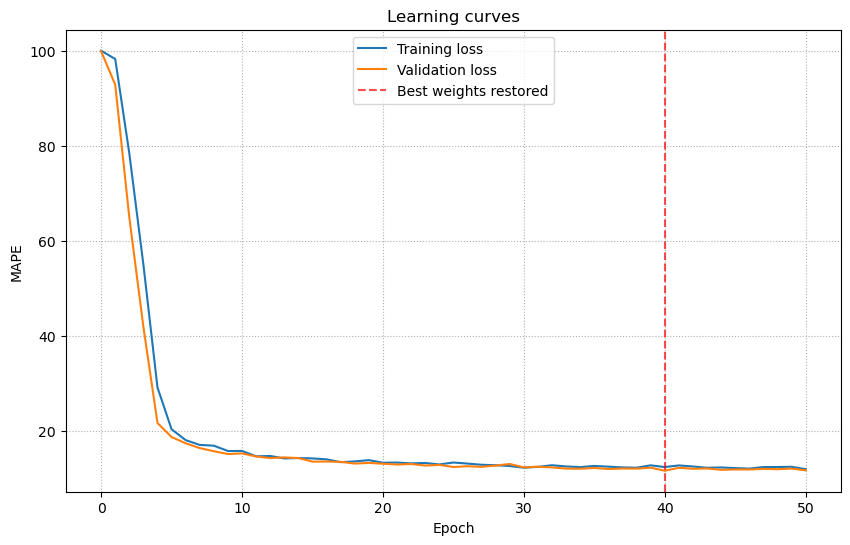

In [20]:
plt.figure(figsize=(10, 6))
plt.plot(history.history['loss'], label='Training loss')
plt.plot(history.history['val_loss'], label='Validation loss')
plt.xlabel('Epoch')
plt.axvline(x=best_epoch, color='red', linestyle='--', alpha=0.7, label='Best weights restored')
plt.ylabel('MAPE')
plt.title('Learning curves')
plt.legend()
plt.grid(True, linestyle=':')
plt.savefig('images/nn_learning_curves.png')
plt.show()

### Dominant factors - Neural Network (permutation-style importance)

                  Feature  Importance
14             1st Flr SF    0.015016
17            Gr Liv Area    0.014223
6            Overall Cond    0.010892
4                Lot Area    0.007410
74   Neighborhood_Crawfor    0.006525
15             2nd Flr SF    0.006400
28            Garage Area    0.006391
10           BsmtFin SF 1    0.005885
5            Overall Qual    0.005707
176         Exter Qual_Ex    0.005021


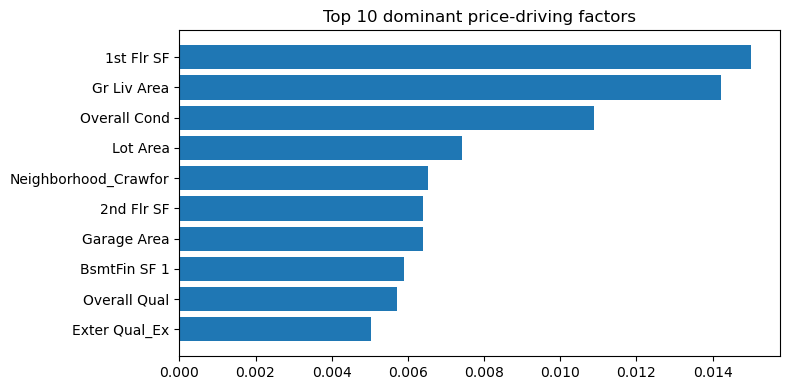

In [21]:
base_pred = model_net.predict(X_test_scaled, verbose=0).flatten()
base_mape = mean_absolute_percentage_error(y_test, base_pred)

feature_importance = []
for i in range(len(X_train_full.columns)):
    X_mixed = X_test_scaled.copy()
    np.random.shuffle(X_mixed[:, i])
    mixed_pred = model_net.predict(X_mixed, verbose=0).flatten()
    mixed_mape = mean_absolute_percentage_error(y_test, mixed_pred)
    feature_importance.append(mixed_mape - base_mape)

factors_net = pd.DataFrame({'Feature': X_train_full.columns, 'Importance': feature_importance})
factors_net['AbsImportance'] = np.abs(factors_net['Importance'])

dominant_factors_net = factors_net.sort_values(by='AbsImportance', ascending=False).head(10)
print(dominant_factors_net[['Feature', 'Importance']])
plot_dominant_factors(dominant_factors_net, 'AbsImportance', 'nn_factors')